Градиентный бустинг (вариант 7) `Heart_Disease_and_Hospitals.csv`

## 1. Подготовка и разведочный анализ данных (EDA)

### 1.1. Загрузка данных и первичный осмотр

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

RANDOM_STATE = 42

file_name = 'Heart_Disease_and_Hospitals.csv'
path = os.path.join('Data', file_name) if os.path.exists(os.path.join('Data', file_name)) else file_name

df = pd.read_csv(path)
print(f"Размер датасета: {df.shape}")
df.head()

Размер датасета: (10000, 15)


,full_name,age,country,state,blood_pressure,cholesterol,bmi,glucose_level,gender,first_name,last_name,hospital,treatment,treatment_date,heart_disease
0,Alice Johnson,21,USA,Utah,138.068129,270.564349,36.101427,63.487954,Female,Alice,Johnson,Starlight Hospital,Physiotherapy,2021-07-07 21:23:23.542872956,1
1,Bob Williams,44,USA,North Dakota,100.383639,160.910030,14.330471,187.008977,Female,Bob,Williams,Maple Leaf Hospital,Counseling,2023-09-13 07:31:37.167014532,0
2,Oliver Jones,22,USA,Iowa,145.618318,208.490251,20.277098,35.903576,Female,Oliver,Jones,Crossroads Health Center,Medication,2019-11-22 03:56:29.389793943,0
3,Quinn Davis,19,USA,Louisiana,152.577870,348.153738,62.712693,31.495166,Female,Quinn,Davis,Springfield General Hospital,Counseling,2021-10-09 23:10:16.253672680,1
4,Alice Martinez,64,USA,Massachusetts,111.793570,200.628925,14.468485,154.513129,Female,Alice,Martinez,Valley View Hospital,Rehabilitation,2018-03-16 04:43:59.950843739,1


### 1.2. Анализ пропусков, дубликатов и баланса классов

In [2]:
print("--- Пропущенные значения по столбцам ---")
print(df.isnull().sum())

print("\n--- Полные дубликаты строк ---")
print(f"Количество дубликатов: {df.duplicated().sum()}")

print("\n--- Распределение целевого класса ---")
print(df['heart_disease'].value_counts().rename({0: 'Здоров (0)', 1: 'Болен (1)'}))
print(f"Доля класса 1 (больные): {df['heart_disease'].mean():.2%}")

num_cols = ['age', 'blood_pressure', 'cholesterol', 'bmi', 'glucose_level']
print("\n--- Описательная статистика числовых признаков ---")
display(df[num_cols].describe().round(2))

--- Пропущенные значения по столбцам ---
full_name         0
age               0
country           0
state             0
blood_pressure    0
cholesterol       0
bmi               0
glucose_level     0
gender            0
first_name        0
last_name         0
hospital          0
treatment         0
treatment_date    0
heart_disease     0
dtype: int64

--- Полные дубликаты строк ---
Количество дубликатов: 0

--- Распределение целевого класса ---
heart_disease
Болен (1)     5007
Здоров (0)    4993
Name: count, dtype: int64
Доля класса 1 (больные): 50.07%

--- Описательная статистика числовых признаков ---


,age,blood_pressure,cholesterol,bmi,glucose_level
count,10000.00,10000.00,10000.00,10000.00,10000.00
mean,48.57,104.84,206.31,21.42,90.24
std,17.96,33.44,95.12,13.01,91.89
min,18.00,10.46,0.18,0.01,-185.81
25%,33.00,81.30,131.38,10.90,13.78
50%,49.00,97.74,213.83,21.06,88.91
75%,64.00,124.32,279.35,28.84,164.70
max,79.00,244.54,539.09,75.31,377.56


### 1.3. Визуализация распределений и анализ аномалий

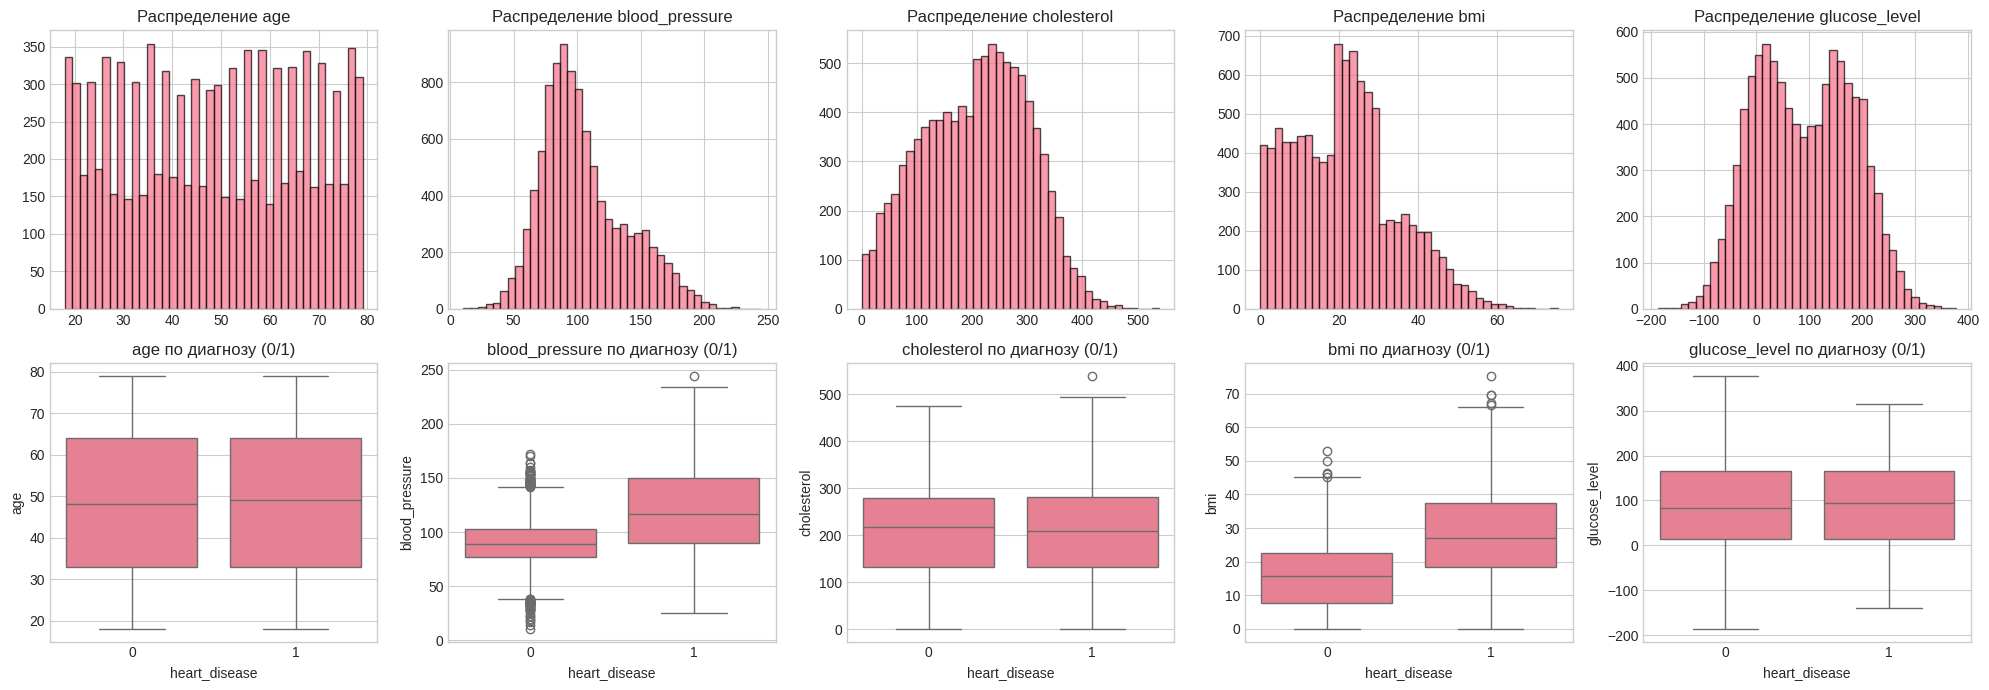

Глюкоза <= 0 : 1939 (19.4%)
ИМТ < 10     : 2282 (22.8%)


In [3]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))

for i, col in enumerate(num_cols):
    axes[0, i].hist(df[col], bins=40, edgecolor='black', alpha=0.7)
    axes[0, i].set_title(f'Распределение {col}')

    sns.boxplot(data=df, x='heart_disease', y=col, ax=axes[1, i])
    axes[1, i].set_title(f'{col} по диагнозу (0/1)')

plt.tight_layout()
plt.show()

print(f"Глюкоза <= 0 : {(df.glucose_level <= 0).sum()} ({(df.glucose_level <= 0).mean():.1%})")
print(f"ИМТ < 10     : {(df.bmi < 10).sum()} ({(df.bmi < 10).mean():.1%})")

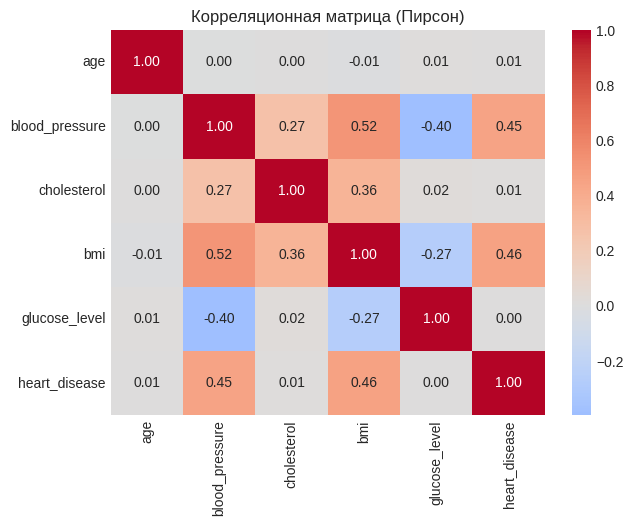

,признак,категорий,chi2,p-value
0,gender,2,0.0,0.934
1,treatment,5,5.5,0.238
2,hospital,49,52.5,0.305
3,state,50,42.3,0.740


Доля больных по годам: {2018: 0.505, 2019: 0.492, 2020: 0.494, 2021: 0.51, 2022: 0.5, 2023: 0.504}


In [5]:
from scipy.stats import chi2_contingency

plt.figure(figsize=(7, 5))
corr = df[num_cols + ['heart_disease']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляционная матрица (Пирсон)')
plt.show()

cat_cols = ['gender', 'treatment', 'hospital', 'state']
rows = []
for c in cat_cols:
    contingency_table = pd.crosstab(df[c], df['heart_disease'])
    chi2, p, dof, _ = chi2_contingency(contingency_table)
    rows.append({
        'признак': c,
        'категорий': df[c].nunique(),
        'chi2': round(chi2, 1),
        'p-value': round(p, 3)
    })
display(pd.DataFrame(rows))

dt = pd.to_datetime(df['treatment_date'])
print('Доля больных по годам:', df.groupby(dt.dt.year)['heart_disease'].mean().round(3).to_dict())

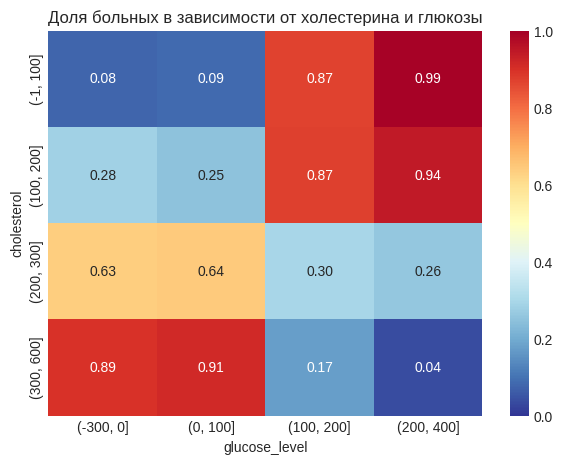

In [6]:
tmp = df.copy()
tmp['chol_bin'] = pd.cut(tmp['cholesterol'], [-1, 100, 200, 300, 600])
tmp['gluc_bin'] = pd.cut(tmp['glucose_level'], [-300, 0, 100, 200, 400])

pivot = tmp.pivot_table(index='chol_bin', columns='gluc_bin', values='heart_disease', aggfunc='mean')

plt.figure(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='RdYlBu_r', vmin=0, vmax=1)
plt.title('Доля больных в зависимости от холестерина и глюкозы')
plt.xlabel('glucose_level')
plt.ylabel('cholesterol')
plt.show()

In [8]:
from sklearn.ensemble import GradientBoostingClassifier

X_raw = df[['age', 'blood_pressure', 'cholesterol', 'bmi', 'glucose_level']].copy()

X_med = X_raw.copy()
X_med.loc[X_med.glucose_level <= 0, 'glucose_level'] = np.nan
X_med.loc[X_med.bmi < 10, 'bmi'] = np.nan
X_med = X_med.fillna(X_med.median())

for name, X_variant in [('Значения как есть', X_raw), ('Аномалии -> медиана', X_med)]:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_variant, df['heart_disease'], test_size=0.25, random_state=RANDOM_STATE, stratify=df['heart_disease']
    )
    test_acc = GradientBoostingClassifier(random_state=RANDOM_STATE).fit(X_tr, y_tr).score(X_te, y_te)
    print(f"{name:22s}: accuracy = {test_acc:.4f}")

Значения как есть     : accuracy = 0.9352
Аномалии -> медиана   : accuracy = 0.9324


### 1.4. Предобработка: очистка признаков, масштабирование и кодирование

In [4]:
data = df.copy()

data['treatment_year'] = pd.to_datetime(data['treatment_date']).dt.year

data = data.drop(columns=[
    'full_name', 'first_name', 'last_name',
    'country',
    'hospital', 'state',
    'treatment_date'
])

X = data.drop(columns=['heart_disease'])
y = data['heart_disease']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

numeric_features = ['age', 'blood_pressure', 'cholesterol', 'bmi', 'glucose_level', 'treatment_year']
categorical_features = ['gender', 'treatment']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_features)
    ]
)

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

ohe_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
all_feature_names = numeric_features + list(ohe_feature_names)

print(f"Исходный размер признаков: {X.shape[1]}")
print(f"Размер после обработки: X_train = {X_train_scaled.shape}, X_test = {X_test_scaled.shape}")
print(f"\nИтоговый список признаков для модели ({len(all_feature_names)} шт.):")
for feat in all_feature_names:
    print(f" - {feat}")

Исходный размер признаков: 8
Размер после обработки: X_train = (7500, 11), X_test = (2500, 11)

Итоговый список признаков для модели (11 шт.):
 - age
 - blood_pressure
 - cholesterol
 - bmi
 - glucose_level
 - treatment_year
 - gender_Male
 - treatment_Medication
 - treatment_Physiotherapy
 - treatment_Rehabilitation
 - treatment_Surgery


## 2. Обучение модели градиентного бустинга с исходными параметрами

In [9]:
from sklearn.ensemble import GradientBoostingClassifier

gb_initial = GradientBoostingClassifier(random_state=RANDOM_STATE)

print("Обучение базовой модели градиентного бустинга...")
gb_initial.fit(X_train_scaled, y_train)
print("Модель успешно обучена!")

y_pred_initial = gb_initial.predict(X_test_scaled)

y_pred_proba_initial = gb_initial.predict_proba(X_test_scaled)[:, 1]

print("\nПараметры базовой модели:")
for param, value in gb_initial.get_params().items():
    if param in ['n_estimators', 'learning_rate', 'max_depth', 'subsample', 'loss', 'min_samples_split']:
        print(f" - {param:18s}: {value}")

Обучение базовой модели градиентного бустинга...
Модель успешно обучена!

Параметры базовой модели:
 - learning_rate     : 0.1
 - loss              : log_loss
 - max_depth         : 3
 - min_samples_split : 2
 - n_estimators      : 100
 - subsample         : 1.0


## 3. Оценка качества

In [10]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report
)

def calculate_metrics(y_true, y_pred, y_proba):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_proba)
    }

metrics_initial = calculate_metrics(y_test, y_pred_initial, y_pred_proba_initial)

print("--- Метрики базовой модели на тестовой выборке ---")
for metric_name, value in metrics_initial.items():
    print(f" {metric_name:10s}: {value:.4f}")

print("\n--- Полный отчет о классификации (Classification Report) ---")
print(classification_report(y_test, y_pred_initial, target_names=['Здоров (0)', 'Болен (1)'], digits=4))

train_acc = gb_initial.score(X_train_scaled, y_train)
test_acc = metrics_initial['Accuracy']
print("--- Проверка на переобучение ---")
print(f"Accuracy на Train : {train_acc:.4f}")
print(f"Accuracy на Test  : {test_acc:.4f}")
print(f"Разница (Train - Test): {(train_acc - test_acc):.4f}")

--- Метрики базовой модели на тестовой выборке ---
 Accuracy  : 0.9356
 Precision : 0.9299
 Recall    : 0.9425
 F1-score  : 0.9361
 ROC-AUC   : 0.9806

--- Полный отчет о классификации (Classification Report) ---
              precision    recall  f1-score   support

  Здоров (0)     0.9415    0.9287    0.9351      1248
   Болен (1)     0.9299    0.9425    0.9361      1252

    accuracy                         0.9356      2500
   macro avg     0.9357    0.9356    0.9356      2500
weighted avg     0.9357    0.9356    0.9356      2500

--- Проверка на переобучение ---
Accuracy на Train : 0.9385
Accuracy на Test  : 0.9356
Разница (Train - Test): 0.0029


## 4. Визуализация результатов

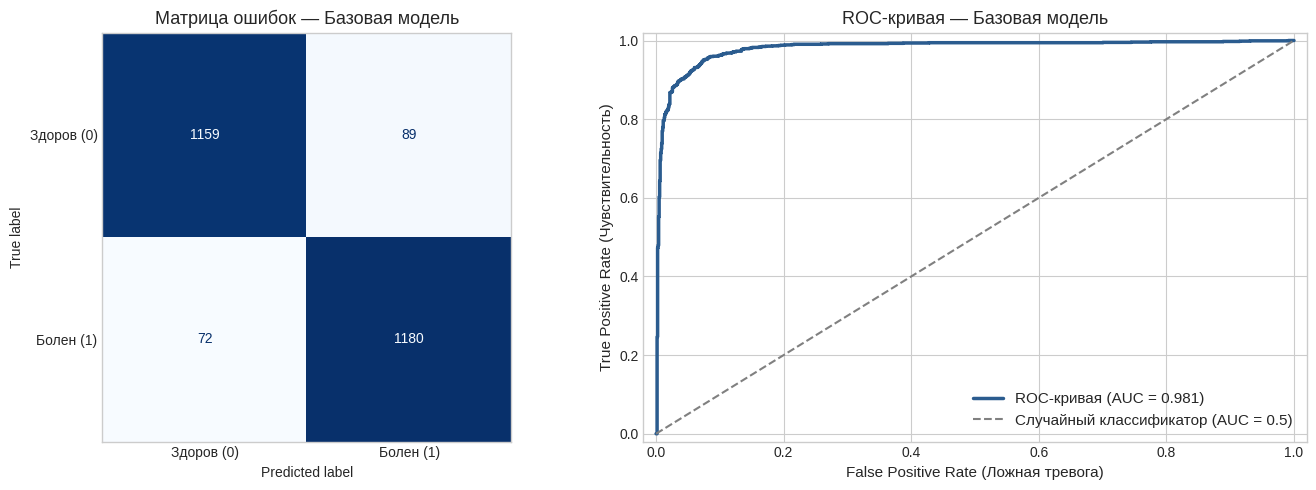

Истинно здоровые (TN) : 1159
Ложная тревога   (FP) : 89 (здоровым ошибочно поставлен диагноз)
Пропуск болезни  (FN) : 72 (больные ошибочно названы здоровыми)
Истинно больные  (TP) : 1180


In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_initial,
    display_labels=['Здоров (0)', 'Болен (1)'],
    cmap='Blues',
    ax=axes[0],
    colorbar=False
)
axes[0].set_title('Матрица ошибок — Базовая модель', fontsize=13)
axes[0].grid(False)

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba_initial)
auc_val = metrics_initial['ROC-AUC']

axes[1].plot(fpr, tpr, color='#2b5c8f', lw=2.5, label=f'ROC-кривая (AUC = {auc_val:.3f})')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Случайный классификатор (AUC = 0.5)')
axes[1].set_xlim([-0.02, 1.02])
axes[1].set_ylim([-0.02, 1.02])
axes[1].set_xlabel('False Positive Rate (Ложная тревога)', fontsize=11)
axes[1].set_ylabel('True Positive Rate (Чувствительность)', fontsize=11)
axes[1].set_title('ROC-кривая — Базовая модель', fontsize=13)
axes[1].legend(loc='lower right', fontsize=11)

plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_initial).ravel()
print(f"Истинно здоровые (TN) : {tn}")
print(f"Ложная тревога   (FP) : {fp} (здоровым ошибочно поставлен диагноз)")
print(f"Пропуск болезни  (FN) : {fn} (больные ошибочно названы здоровыми)")
print(f"Истинно больные  (TP) : {tp}")

## 5. Настройка гиперпараметров модели
1. `max_depth`
2. `learning_rate`
3. `n_estimators`
4. `subsample`

In [14]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

param_grid = {
    'n_estimators':  [100, 200, 300],
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth':     [3, 4, 5],
    'subsample':     [1.0],
}
n_combos = int(np.prod([len(v) for v in param_grid.values()]))
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
print('Сетка параметров:')
for k, v in param_grid.items():
    print(f'  {k}: {v}')
print(f'Всего комбинаций: {n_combos}, при 3-fold CV это {n_combos * 3} обучений')

Сетка параметров:
  n_estimators: [100, 200, 300]
  learning_rate: [0.05, 0.1, 0.2]
  max_depth: [3, 4, 5]
  subsample: [1.0]
Всего комбинаций: 27, при 3-fold CV это 81 обучений


## 6. Подбор оптимальных гиперпараметров с помощью GridSearchCV

In [18]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=1,
    verbose=2
)

print("Запуск турнира гиперпараметров (GridSearchCV)...")
grid_search.fit(X_train_scaled, y_train)

print("\n--- Поиск успешно завершен! ---")
print(f"Лучшие найденные параметры: {grid_search.best_params_}")
print(f"Лучший средний F1-score на кросс-валидации: {grid_search.best_score_:.4f}")

cv_res = pd.DataFrame(grid_search.cv_results_)
cols_to_show = [
    'param_n_estimators', 'param_learning_rate', 'param_max_depth',
    'param_subsample', 'mean_test_score', 'std_test_score', 'rank_test_score'
]

top10_df = cv_res.sort_values('rank_test_score')[cols_to_show].head(10).reset_index(drop=True)
top10_df.columns = ['n_estimators', 'learning_rate', 'max_depth', 'subsample', 'F1 (CV Mean)', 'F1 (CV Std)', 'Место в рейтинге']

print("\n--- Топ-10 лучших комбинаций параметров ---")
display(top10_df.round(4))

Запуск турнира гиперпараметров (GridSearchCV)...
Fitting 3 folds for each of 27 candidates, totalling 81 fits
[CV] END learning_rate=0.05, max_depth=3, n_estimators=100, subsample=1.0; total time=   1.4s
[CV] END learning_rate=0.05, max_depth=3, n_estimators=100, subsample=1.0; total time=   1.4s
[CV] END learning_rate=0.05, max_depth=3, n_estimators=100, subsample=1.0; total time=   1.4s
[CV] END learning_rate=0.05, max_depth=3, n_estimators=200, subsample=1.0; total time=   2.7s
[CV] END learning_rate=0.05, max_depth=3, n_estimators=200, subsample=1.0; total time=   2.8s
[CV] END learning_rate=0.05, max_depth=3, n_estimators=200, subsample=1.0; total time=   4.1s
[CV] END learning_rate=0.05, max_depth=3, n_estimators=300, subsample=1.0; total time=   4.1s
[CV] END learning_rate=0.05, max_depth=3, n_estimators=300, subsample=1.0; total time=   4.1s
[CV] END learning_rate=0.05, max_depth=3, n_estimators=300, subsample=1.0; total time=   5.4s
[CV] END learning_rate=0.05, max_depth=4, n_

,n_estimators,learning_rate,max_depth,subsample,F1 (CV Mean),F1 (CV Std),Место в рейтинге
0,300,0.10,5,1.0,0.9320,0.0023,1
1,200,0.10,5,1.0,0.9319,0.0026,2
2,100,0.05,5,1.0,0.9315,0.0014,3
3,100,0.10,5,1.0,0.9312,0.0021,4
4,200,0.05,5,1.0,0.9310,0.0018,5
5,300,0.05,5,1.0,0.9301,0.0026,6
6,300,0.20,5,1.0,0.9298,0.0019,7
7,200,0.10,4,1.0,0.9296,0.0022,8
8,200,0.20,5,1.0,0.9295,0.0008,9
9,300,0.10,4,1.0,0.9290,0.0024,10


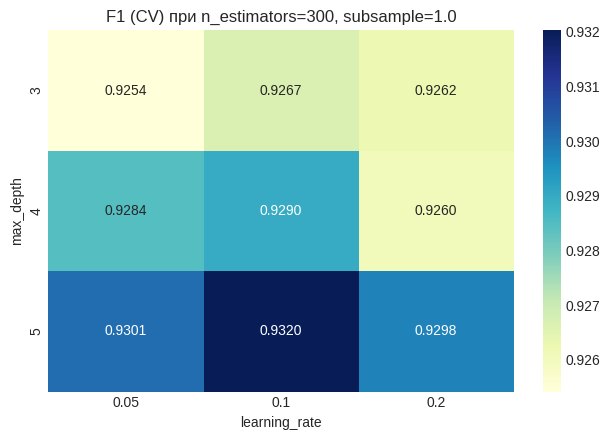

In [19]:
best_n = grid_search.best_params_['n_estimators']
best_sub = grid_search.best_params_['subsample']

sub_results = cv_res[
    (cv_res.param_n_estimators == best_n) &
    (cv_res.param_subsample == best_sub)
]

heatmap_data = sub_results.pivot_table(
    index='param_max_depth',
    columns='param_learning_rate',
    values='mean_test_score'
)

plt.figure(figsize=(6.5, 4.5))
sns.heatmap(heatmap_data, annot=True, fmt='.4f', cmap='YlGnBu')
plt.title(f'F1 (CV) при n_estimators={best_n}, subsample={best_sub}')
plt.xlabel('learning_rate')
plt.ylabel('max_depth')
plt.tight_layout()
plt.show()

## 7. Повторное обучение и оценка модели с оптимизированными параметрами

In [20]:
import pandas as pd

best_gb = grid_search.best_estimator_

y_pred_best = best_gb.predict(X_test_scaled)
y_pred_proba_best = best_gb.predict_proba(X_test_scaled)[:, 1]

metrics_best = calculate_metrics(y_test, y_pred_best, y_pred_proba_best)

comparison_df = pd.DataFrame({
    'Исходная модель': metrics_initial,
    'Настроенная модель': metrics_best
})
comparison_df['Прирост'] = comparison_df['Настроенная модель'] - comparison_df['Исходная модель']

print("--- Сравнительная таблица метрик на тестовой выборке ---")
display(comparison_df.round(4))

train_acc_best = best_gb.score(X_train_scaled, y_train)
test_acc_best = metrics_best['Accuracy']

print("\n--- Проверка переобучения настроенной модели ---")
print(f"Accuracy на Train : {train_acc_best:.4f}")
print(f"Accuracy на Test  : {test_acc_best:.4f}")
print(f"Зазор (Train - Test): {(train_acc_best - test_acc_best):.4f}")

--- Сравнительная таблица метрик на тестовой выборке ---


,Исходная модель,Настроенная модель,Прирост
Accuracy,0.9356,0.9424,0.0068
Precision,0.9299,0.9369,0.0070
Recall,0.9425,0.9489,0.0064
F1-score,0.9361,0.9429,0.0067
ROC-AUC,0.9806,0.9848,0.0042



--- Проверка переобучения настроенной модели ---
Accuracy на Train : 0.9969
Accuracy на Test  : 0.9424
Зазор (Train - Test): 0.0545


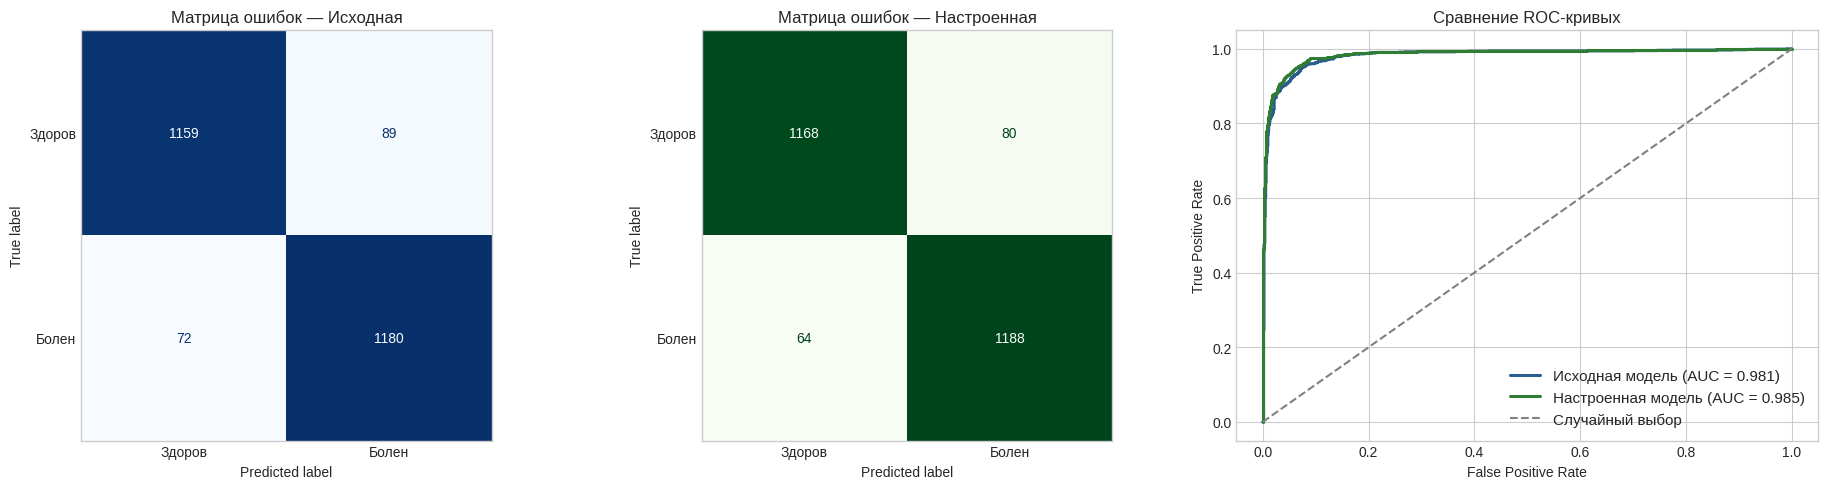

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, roc_auc_score

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_initial,
    display_labels=['Здоров', 'Болен'],
    cmap='Blues',
    ax=axes[0],
    colorbar=False
)
axes[0].set_title('Матрица ошибок — Исходная', fontsize=12)
axes[0].grid(False)

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best,
    display_labels=['Здоров', 'Болен'],
    cmap='Greens',
    ax=axes[1],
    colorbar=False
)
axes[1].set_title('Матрица ошибок — Настроенная', fontsize=12)
axes[1].grid(False)

for proba, label, color in [
    (y_pred_proba_initial, 'Исходная модель', '#2b5c8f'),
    (y_pred_proba_best, 'Настроенная модель', '#2e7d32')
]:
    fpr_c, tpr_c, _ = roc_curve(y_test, proba)
    auc_score = roc_auc_score(y_test, proba)
    axes[2].plot(fpr_c, tpr_c, lw=2.2, color=color, label=f'{label} (AUC = {auc_score:.3f})')

axes[2].plot([0, 1], [0, 1], 'k--', color='gray', label='Случайный выбор')
axes[2].set_xlabel('False Positive Rate')
axes[2].set_ylabel('True Positive Rate')
axes[2].set_title('Сравнение ROC-кривых', fontsize=12)
axes[2].legend(loc='lower right', fontsize=11)

plt.tight_layout()
plt.show()

## 8. Исследование влияния скорости обучения (learning_rate) и количества деревьев

Обучение моделей для исследования learning_rate...
 -> Обучение для lr = 0.01 (до 400 деревьев)...
 -> Обучение для lr = 0.05 (до 400 деревьев)...
 -> Обучение для lr = 0.1 (до 400 деревьев)...
 -> Обучение для lr = 0.2 (до 400 деревьев)...
 -> Обучение для lr = 0.5 (до 400 деревьев)...
Все модели успешно обучены!


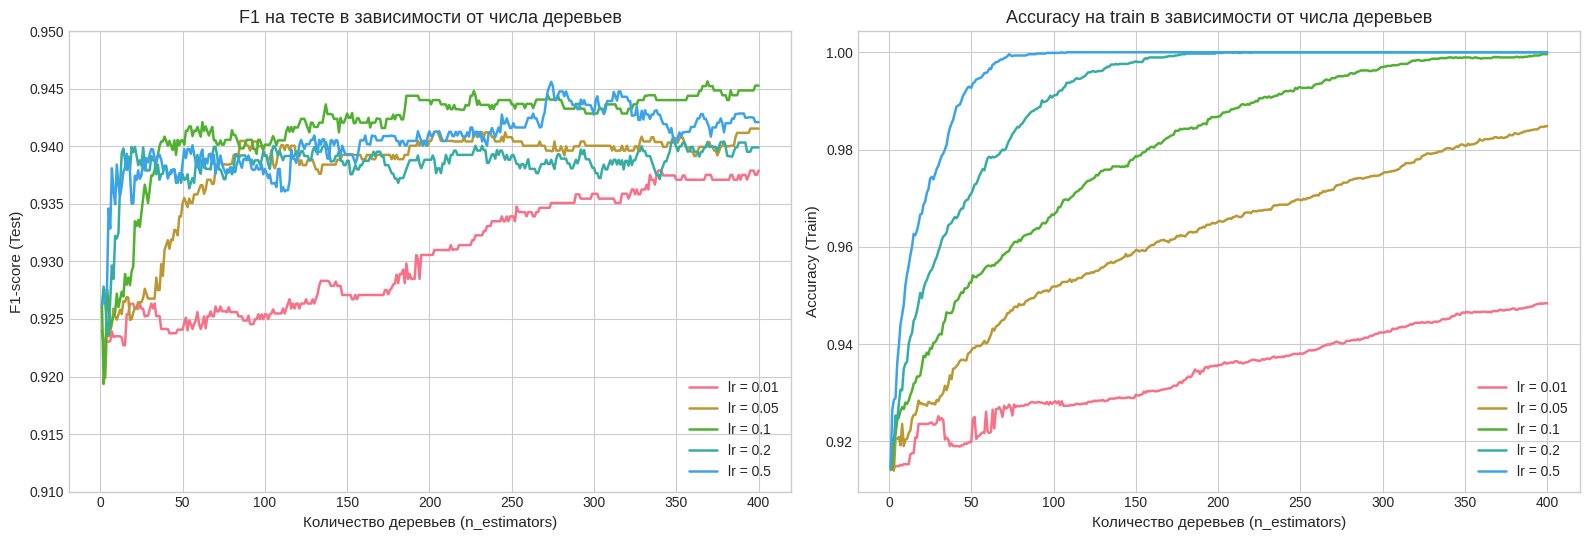

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import f1_score, accuracy_score

learning_rates = [0.01, 0.05, 0.1, 0.2, 0.5]
N_MAX = 400

fixed_depth = best_gb.max_depth
fixed_subsample = best_gb.subsample

curves = {}

print("Обучение моделей для исследования learning_rate...")
for lr in learning_rates:
    print(f" -> Обучение для lr = {lr} (до {N_MAX} деревьев)...")
    m = GradientBoostingClassifier(
        learning_rate=lr,
        n_estimators=N_MAX,
        max_depth=fixed_depth,
        subsample=fixed_subsample,
        random_state=RANDOM_STATE
    )
    m.fit(X_train_scaled, y_train)

    curves[lr] = {
        'test_f1': [f1_score(y_test, p) for p in m.staged_predict(X_test_scaled)],
        'train_acc': [accuracy_score(y_train, p) for p in m.staged_predict(X_train_scaled)]
    }

print("Все модели успешно обучены!")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

for lr in learning_rates:
    axes[0].plot(range(1, N_MAX + 1), curves[lr]['test_f1'], label=f'lr = {lr}', lw=1.8)
    axes[1].plot(range(1, N_MAX + 1), curves[lr]['train_acc'], label=f'lr = {lr}', lw=1.8)

axes[0].set_title('F1 на тесте в зависимости от числа деревьев', fontsize=13)
axes[0].set_xlabel('Количество деревьев (n_estimators)', fontsize=11)
axes[0].set_ylabel('F1-score (Test)', fontsize=11)
axes[0].set_ylim(0.91, 0.95)
axes[0].legend(loc='lower right', fontsize=10)

axes[1].set_title('Accuracy на train в зависимости от числа деревьев', fontsize=13)
axes[1].set_xlabel('Количество деревьев (n_estimators)', fontsize=11)
axes[1].set_ylabel('Accuracy (Train)', fontsize=11)
axes[1].legend(loc='lower right', fontsize=10)

plt.tight_layout()
plt.show()

In [23]:
import pandas as pd

checkpoints = [10, 50, 100, 200, 300, 400]

table_data = {}
for lr in learning_rates:
    table_data[f'lr = {lr}'] = [curves[lr]['test_f1'][n - 1] for n in checkpoints]

summary_f1_table = pd.DataFrame(table_data, index=pd.Index(checkpoints, name='n_estimators'))

print("--- Значения F1-score на тесте в контрольных точках ---")
display(summary_f1_table.round(4))

best_col = summary_f1_table.max().idxmax()
best_row = summary_f1_table[best_col].idxmax()
print(f"\nАбсолютный пик в таблице: {best_col}, n_estimators = {best_row} -> F1 = {summary_f1_table.loc[best_row, best_col]:.4f}")

--- Значения F1-score на тесте в контрольных точках ---


,lr = 0.01,lr = 0.05,lr = 0.1,lr = 0.2,lr = 0.5
n_estimators,,,,,
10,0.9235,0.9249,0.9272,0.9320,0.9384
50,0.9241,0.9351,0.9405,0.9376,0.9386
100,0.9254,0.9393,0.9402,0.9392,0.9380
200,0.9306,0.9405,0.9440,0.9388,0.9413
300,0.9359,0.9401,0.9429,0.9381,0.9428
400,0.9379,0.9416,0.9453,0.9399,0.9421



Абсолютный пик в таблице: lr = 0.1, n_estimators = 400 -> F1 = 0.9453


## 9. Анализ важности признаков

--- Сравнительная таблица важности признаков ---


,Impurity-based (MDI),Permutation (Test)
cholesterol,0.3593,0.1946
bmi,0.2649,0.1227
blood_pressure,0.2169,0.1748
glucose_level,0.1485,0.2039
age,0.0049,-0.0009
treatment_year,0.0021,-0.0006
gender_Male,0.0010,-0.0008
treatment_Surgery,0.0007,-0.0008
treatment_Medication,0.0006,0.0000
treatment_Physiotherapy,0.0006,-0.0001


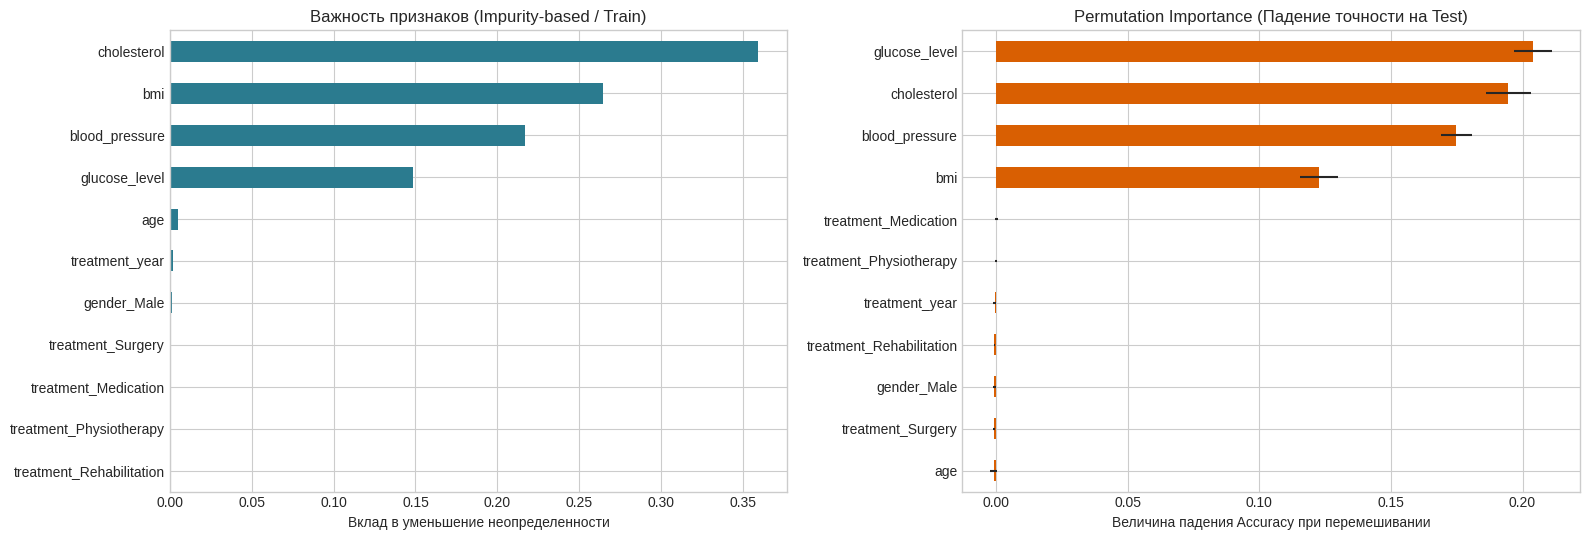

In [24]:
from sklearn.inspection import permutation_importance
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

imp_gini = pd.Series(best_gb.feature_importances_, index=all_feature_names)

perm = permutation_importance(
    best_gb,
    X_test_scaled,
    y_test,
    n_repeats=10,
    scoring='accuracy',
    random_state=RANDOM_STATE
)
imp_perm = pd.Series(perm.importances_mean, index=all_feature_names)

imp_df = pd.DataFrame({
    'Impurity-based (MDI)': imp_gini,
    'Permutation (Test)': imp_perm
}).sort_values('Impurity-based (MDI)', ascending=False)

print("--- Сравнительная таблица важности признаков ---")
display(imp_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

imp_df['Impurity-based (MDI)'].sort_values().plot.barh(ax=axes[0], color='#2b7b8f')
axes[0].set_title('Важность признаков (Impurity-based / Train)', fontsize=12)
axes[0].set_xlabel('Вклад в уменьшение неопределенности', fontsize=10)

imp_df['Permutation (Test)'].sort_values().plot.barh(
    ax=axes[1],
    color='#d95f02',
    xerr=pd.Series(perm.importances_std, index=all_feature_names)[imp_df['Permutation (Test)'].sort_values().index]
)
axes[1].set_title('Permutation Importance (Падение точности на Test)', fontsize=12)
axes[1].set_xlabel('Величина падения Accuracy при перемешивании', fontsize=10)

plt.tight_layout()
plt.show()